# autoencoder_training_v6

Run the cells in order. Keep `autoencoder_v6_common.py` in the same folder as these notebooks.

## Why v6
v5 gave no gain over v4 (recall 0.709 at 3% FPR in both). Its per-family results show why: **PortScan alone is 74% of all missed attacks**, and PortScan + SSH-Patator + web attacks are 78% of misses. Together they cap recall at about 0.77 no matter how well DoS/DDoS are tuned. Architecture and loss tuning cannot fix that, so v6 targets the cause.

## What changed
1. **Destination Port encoding.** The raw port number, once standardised, makes ports 22, 53, 80 and 443 almost identical (std is about 20,000). v6 can instead feed *port rarity in benign training traffic* plus well-known / registered / dynamic flags. `PORT_MODES = ['raw', 'engineered']` makes this an ablation, so the calibration set tells you whether it helped.
2. **Isolation Forest and score fusion.** Adds an Isolation Forest score and tail-probability fusion with the autoencoder score (each score converted to a benign p-value, then summed).
3. **Selection metric matches the goal.** Candidates are ranked by mean calibration TPR at 1% / 3% / 5% FPR, not PR-AUC.
4. **Seed ensemble.** The winning configuration is retrained with several seeds and the scores are averaged to cut run-to-run variance (v5 PR-AUC varied by about 0.07 between near-identical configs).
5. **Smaller grid.** Dropped what v5 showed never helped: `standard` scaling, Huber loss, `latent_mahal`, `normalized_mae`. 12 trials instead of 24.
6. Same calibration / hold-out split as v5 (`SPLIT_TAG='v5'`), so v5 and v6 are scored on identical hold-out rows.

## 1. Imports and paths

In [1]:
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Dense, GaussianNoise
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score
from autoencoder_v6_common import (VERSION, SPLIT_TAG, FEATURES, validate_frame, fit_preprocessing, transform,
                                   residual_scales, ensemble_base_scores, all_scores, benign_threshold, tpr_at_fpr)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
PROJECT_ROOT = Path('..')  # Adjust to match your project layout
DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'Data_V2'
TRAIN_FILE = DATA_DIR / 'autoencoder_benign_train.parquet'
VAL_FILE = DATA_DIR / 'autoencoder_benign_validation.parquet'
KNOWN_TEST_FILE = DATA_DIR / 'known_test.parquet'
# Split files come from v5 (reused if present, created identically otherwise).
CALIBRATION_FILE = DATA_DIR / f'autoencoder_{SPLIT_TAG}_calibration.parquet'
HOLDOUT_FILE = DATA_DIR / f'autoencoder_{SPLIT_TAG}_known_test_holdout.parquet'
MODEL_DIR = PROJECT_ROOT / 'saved-models' / f'autoencoder_{VERSION}'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results' / f'autoencoder_{VERSION}'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CAL_FRACTION = 0.5
TARGET_FPR = 0.03             # reporting operating point (same as v4/v5)
FPR_OPTIONS = [0.01, 0.03, 0.05]
QUICK_RUN = False             # True = tiny smoke test

for p in (TRAIN_FILE, VAL_FILE):
    if not p.exists(): raise FileNotFoundError(p.resolve())
print('Version:', VERSION, '| split tag:', SPLIT_TAG, '| raw features:', len(FEATURES))

Version: v6 | split tag: v5 | raw features: 69


## 2. Calibration / hold-out split (reused from v5 when it exists)

In [2]:
if not (CALIBRATION_FILE.exists() and HOLDOUT_FILE.exists()):
    kt = pd.read_parquet(KNOWN_TEST_FILE).reset_index(drop=True)
    kt.columns = kt.columns.astype(str).str.strip()
    kt['Label'] = kt['Label'].astype(str).str.strip()
    cal_idx = []
    for label, g in kt.groupby('Label'):
        g = g.sample(frac=1, random_state=SEED)
        n_cal = int(round(len(g) * CAL_FRACTION))
        n_cal = min(max(n_cal, 1), len(g) - 1) if len(g) >= 2 else 0
        cal_idx.extend(g.index[:n_cal])
    cal_df = kt.loc[cal_idx]; hold_df = kt.drop(index=cal_idx)
    assert set(cal_df.index).isdisjoint(hold_df.index)
    cal_df.to_parquet(CALIBRATION_FILE, index=False); hold_df.to_parquet(HOLDOUT_FILE, index=False)
    print('Split written. Calibration:', len(cal_df), 'Hold-out:', len(hold_df))
else:
    print('Reusing existing split:', CALIBRATION_FILE.name, '/', HOLDOUT_FILE.name)

Reusing existing split: autoencoder_v5_calibration.parquet / autoencoder_v5_known_test_holdout.parquet


## 3. Load benign training / validation and calibration

In [3]:
train_df, X_train = validate_frame(pd.read_parquet(TRAIN_FILE), 'train', benign_only=True)
val_df, X_val = validate_frame(pd.read_parquet(VAL_FILE), 'validation', benign_only=True)
calibration_df, X_cal = validate_frame(pd.read_parquet(CALIBRATION_FILE), 'calibration')
y_cal = (~calibration_df['Label'].astype(str).str.strip().str.upper().eq('BENIGN')).astype(int).to_numpy()
if len(np.unique(y_cal)) < 2: raise ValueError('Calibration needs benign and attack examples')
print('Train:', X_train.shape, 'Validation:', X_val.shape)
print('Calibration:', X_cal.shape, 'benign:', int((y_cal == 0).sum()), 'attacks:', int((y_cal == 1).sum()))

Train: (1465952, 69) Validation: (314133, 69)
Calibration: (187962, 69) benign: 157066 attacks: 30896


## 4. Configuration and helpers

In [4]:
MODE = 'signedlog_standard'           # clearly beat 'standard' in every v5 comparison
PORT_MODES = ['raw', 'engineered']    # ablation: does port encoding help?
ARCHITECTURES = [((32, 16), 8), ((48, 24), 12), ((64, 32), 16)]
NOISE_OPTIONS = [0.0, 0.05]
ENSEMBLE_SEEDS = [42, 43, 44]
EPOCHS = 100; BATCH_SIZE = 1024; PRED_BATCH_SIZE = 4096
IF_TREES = 300; IF_MAX_SAMPLES = 1024; IF_FIT_ROWS = 300_000
if QUICK_RUN:
    PORT_MODES = ['raw', 'engineered']; ARCHITECTURES = ARCHITECTURES[:1]; NOISE_OPTIONS = [0.0]
    ENSEMBLE_SEEDS = [42, 43]; EPOCHS = 3; IF_TREES = 50; IF_FIT_ROWS = 20_000
assert TARGET_FPR in FPR_OPTIONS

def make_model(input_dim, hidden, latent, noise=0.0):
    inputs = Input(shape=(input_dim,))
    x = GaussianNoise(noise)(inputs) if noise else inputs
    for units in hidden:
        x = Dense(units, activation='relu')(x)
    x = Dense(latent, activation='linear', name='bottleneck')(x)
    for units in reversed(hidden):
        x = Dense(units, activation='relu')(x)
    outputs = Dense(input_dim, activation='linear')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

def fit_ae(xtr, xval, hidden, latent, noise, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = make_model(xtr.shape[1], hidden, latent, noise)
    history = model.fit(xtr, xtr, validation_data=(xval, xval), epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
        callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
                   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)])
    return model, history

def fit_iforest(xtr):
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(xtr), size=min(IF_FIT_ROWS, len(xtr)), replace=False)
    return IsolationForest(n_estimators=IF_TREES, max_samples=IF_MAX_SAMPLES, random_state=SEED, n_jobs=-1).fit(xtr[idx])

def evaluate_candidates(val_all, cal_all, extra):
    rows = []
    for name, s in cal_all.items():
        tprs = tpr_at_fpr(y_cal, s, FPR_OPTIONS)
        rows.append({**extra, 'score': name, 'cal_avg_tpr': float(np.mean(tprs)),
                     **{f'cal_tpr_at_{int(f*100)}pct': float(t) for f, t in zip(FPR_OPTIONS, tprs)},
                     'cal_roc_auc': float(roc_auc_score(y_cal, s)), 'cal_pr_auc': float(average_precision_score(y_cal, s))})
    return rows
print('Trials:', len(PORT_MODES) * len(ARCHITECTURES) * len(NOISE_OPTIONS), '+ final ensemble of', len(ENSEMBLE_SEEDS), 'seeds')

Trials: 12 + final ensemble of 3 seeds


## 5. Tune: port encoding x architecture x noise

Every trained model is scored with 5 reconstruction scores, the Isolation Forest, and 3 fused scores. Candidates are ranked on **calibration** by mean TPR at 1/3/5% FPR. Thresholds still come only from benign validation.

In [5]:
records = []
for port_mode in PORT_MODES:
    prep = fit_preprocessing(X_train, MODE, port_mode)
    xtr = transform(X_train, prep); xval = transform(X_val, prep); xcal = transform(X_cal, prep)
    iforest = fit_iforest(xtr)
    if_val = -iforest.score_samples(xval); if_cal = -iforest.score_samples(xcal)
    print(f'[{port_mode}] input dim = {xtr.shape[1]}; Isolation Forest fitted')
    for hidden, latent in ARCHITECTURES:
        for noise in NOISE_OPTIONS:
            model, history = fit_ae(xtr, xval, hidden, latent, noise, SEED)
            scales = [residual_scales(xval, model.predict(xval, batch_size=PRED_BATCH_SIZE, verbose=0))]
            val_all, refs = all_scores(ensemble_base_scores([model], scales, xval, PRED_BATCH_SIZE), if_val)
            cal_all, _ = all_scores(ensemble_base_scores([model], scales, xcal, PRED_BATCH_SIZE), if_cal, refs)
            extra = {'mode': MODE, 'port_mode': port_mode, 'hidden': list(hidden), 'latent': latent, 'noise': noise,
                     'validation_mse': float(val_all['mse'].mean()), 'epochs': len(history.history['loss'])}
            rows = evaluate_candidates(val_all, cal_all, extra)
            records.extend(rows)
            top = max(rows, key=lambda r: r['cal_avg_tpr'])
            print(f"  {hidden} {latent} noise={noise} | val MSE={extra['validation_mse']:.5f} | best score={top['score']} "
                  f"| avg TPR@1/3/5%={top['cal_avg_tpr']:.4f} (3%: {top['cal_tpr_at_3pct']:.4f})")
comparison = pd.DataFrame(records)
comparison.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_tuning_comparison.csv', index=False)
best = comparison.sort_values('cal_avg_tpr', ascending=False).iloc[0].to_dict()
print('Best single-model candidate:', {k: best[k] for k in ('port_mode', 'hidden', 'latent', 'noise', 'score', 'cal_avg_tpr', 'cal_tpr_at_3pct')})

[raw] input dim = 69; Isolation Forest fitted

  (32, 16) 8 noise=0.0 | val MSE=0.02505 | best score=mae | avg TPR@1/3/5%=0.6521 (3%: 0.6852)
  (32, 16) 8 noise=0.05 | val MSE=0.03323 | best score=mae | avg TPR@1/3/5%=0.6685 (3%: 0.6722)
  (48, 24) 12 noise=0.0 | val MSE=0.01061 | best score=mse | avg TPR@1/3/5%=0.7222 (3%: 0.7105)
  (48, 24) 12 noise=0.05 | val MSE=0.01038 | best score=mae | avg TPR@1/3/5%=0.6662 (3%: 0.6724)
  (64, 32) 16 noise=0.0 | val MSE=0.00497 | best score=p95_mean | avg TPR@1/3/5%=0.6787 (3%: 0.6859)
  (64, 32) 16 noise=0.05 | val MSE=0.00540 | best score=p95_mean | avg TPR@1/3/5%=0.6627 (3%: 0.6836)
[engineered] input dim = 72; Isolation Forest fitted
  (32, 16) 8 noise=0.0 | val MSE=0.03513 | best score=mse | avg TPR@1/3/5%=0.6537 (3%: 0.6737)
  (32, 16) 8 noise=0.05 | val MSE=0.03242 | best score=mae | avg TPR@1/3/5%=0.6278 (3%: 0.6058)
  (48, 24) 12 noise=0.0 | val MSE=0.01112 | best score=mse | avg TPR@1/3/5%=0.7247 (3%: 0.7509)
  (48, 24) 12 noise=0.05 |

### Ablation: did port encoding / fusion help? (best candidate per group, calibration)

In [6]:
by_port = comparison.groupby('port_mode')[['cal_avg_tpr', 'cal_tpr_at_3pct', 'cal_roc_auc']].max()
by_score = comparison.groupby('score')[['cal_avg_tpr', 'cal_tpr_at_3pct', 'cal_roc_auc']].max().sort_values('cal_avg_tpr', ascending=False)
print(by_port); print(); print(by_score)
by_port.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_ablation_port.csv'); by_score.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_ablation_score.csv')

            cal_avg_tpr  cal_tpr_at_3pct  cal_roc_auc
port_mode                                            
engineered     0.724668         0.750874     0.974699
raw            0.722240         0.710480     0.967414

                      cal_avg_tpr  cal_tpr_at_3pct  cal_roc_auc
score                                                          
mse                      0.724668         0.750874     0.974699
mae                      0.720978         0.719511     0.973062
fuse_mse_p95top5         0.710049         0.737701     0.972128
p95_mean                 0.694426         0.710027     0.970077
p95_top5                 0.687414         0.745436     0.967904
max_abs                  0.686756         0.697760     0.969609
fuse_mse_iforest         0.636512         0.668209     0.960019
fuse_p95top5_iforest     0.635249         0.662481     0.954774
iforest                  0.420141         0.543145     0.916013


## 6. Final fit: seed ensemble of the winning configuration

The winning preprocessing / architecture is retrained with each seed in `ENSEMBLE_SEEDS`; each score is averaged across seeds, and the score type is re-chosen on calibration.

In [7]:
port_mode = best['port_mode']; hidden = tuple(best['hidden']); latent = int(best['latent']); noise = float(best['noise'])
prep = fit_preprocessing(X_train, MODE, port_mode)
xtr = transform(X_train, prep); xval = transform(X_val, prep); xcal = transform(X_cal, prep)
iforest = fit_iforest(xtr)
if_val = -iforest.score_samples(xval); if_cal = -iforest.score_samples(xcal)

models, scales_list, first_history = [], [], None
for seed in ENSEMBLE_SEEDS:
    model, history = fit_ae(xtr, xval, hidden, latent, noise, seed)
    models.append(model)
    scales_list.append(residual_scales(xval, model.predict(xval, batch_size=PRED_BATCH_SIZE, verbose=0)))
    if first_history is None: first_history = history.history
    print('trained seed', seed, 'epochs', len(history.history['loss']))

val_all, refs = all_scores(ensemble_base_scores(models, scales_list, xval, PRED_BATCH_SIZE), if_val)
cal_all, _ = all_scores(ensemble_base_scores(models, scales_list, xcal, PRED_BATCH_SIZE), if_cal, refs)
final_rows = evaluate_candidates(val_all, cal_all, {'seeds': len(models)})
final_table = pd.DataFrame(final_rows).sort_values('cal_avg_tpr', ascending=False)
final_table.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_ensemble_candidates.csv', index=False)
print(final_table[['score', 'cal_avg_tpr', 'cal_tpr_at_1pct', 'cal_tpr_at_3pct', 'cal_tpr_at_5pct', 'cal_roc_auc', 'cal_pr_auc']].to_string(index=False))
chosen = final_table.iloc[0]
print(f"\nSingle-model best avg TPR: {best['cal_avg_tpr']:.4f} | ensemble best avg TPR: {chosen['cal_avg_tpr']:.4f} (score={chosen['score']})")

trained seed 42 epochs 100
trained seed 43 epochs 100
trained seed 44 epochs 100
               score  cal_avg_tpr  cal_tpr_at_1pct  cal_tpr_at_3pct  cal_tpr_at_5pct  cal_roc_auc  cal_pr_auc
                 mse     0.684404         0.569977         0.716889         0.766345     0.967077    0.873854
                 mae     0.678783         0.603476         0.686723         0.746148     0.964711    0.869660
            p95_mean     0.669105         0.596291         0.685979         0.725045     0.961554    0.861018
    fuse_mse_p95top5     0.668166         0.561529         0.711354         0.731616     0.963476    0.862115
             max_abs     0.659924         0.578780         0.679247         0.721744     0.958539    0.844473
            p95_top5     0.658316         0.552725         0.691837         0.730386     0.958603    0.844946
    fuse_mse_iforest     0.624407         0.525634         0.657690         0.689895     0.953637    0.820071
fuse_p95top5_iforest     0.599603      

## 7. Save artifacts and training curve

{
  "version": "v6",
  "mode": "signedlog_standard",
  "port_mode": "engineered",
  "hidden": [
    48,
    24
  ],
  "latent": 12,
  "noise": 0.0,
  "seeds": [
    42,
    43,
    44
  ],
  "score": "mse",
  "target_fpr": 0.03,
  "threshold": 0.05095853030681598,
  "thresholds": {
    "0.01": 0.10572802394628475,
    "0.03": 0.05095853030681598,
    "0.05": 0.03715727180242536
  },
  "calibration_avg_tpr": 0.6844035905403073,
  "calibration_tpr_at_3pct": 0.7168889176592439,
  "model_files": [
    "autoencoder_v6_model_seed42.keras",
    "autoencoder_v6_model_seed43.keras",
    "autoencoder_v6_model_seed44.keras"
  ]
}


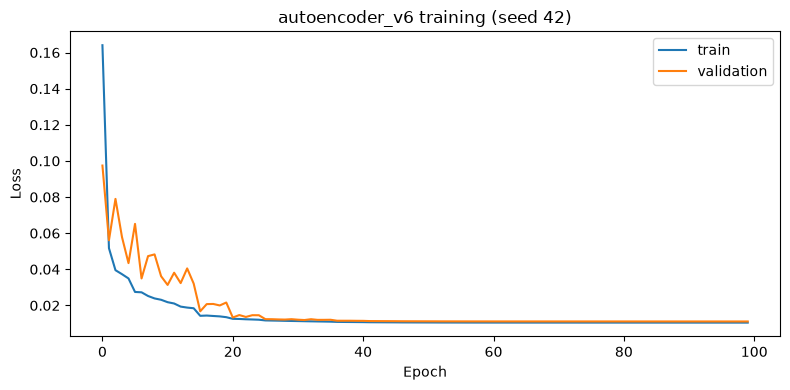

Model artifacts: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\saved-models\autoencoder_v6
Results: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v6


In [8]:
score_name = chosen['score']
thresholds = {f: benign_threshold(val_all[score_name], f) for f in FPR_OPTIONS}
selection = {'version': VERSION, 'mode': MODE, 'port_mode': port_mode, 'hidden': list(hidden), 'latent': latent,
             'noise': noise, 'seeds': ENSEMBLE_SEEDS, 'score': score_name, 'target_fpr': TARGET_FPR,
             'threshold': thresholds[TARGET_FPR], 'thresholds': {str(f): t for f, t in thresholds.items()},
             'calibration_avg_tpr': float(chosen['cal_avg_tpr']), 'calibration_tpr_at_3pct': float(chosen['cal_tpr_at_3pct']),
             'model_files': [f'autoencoder_{VERSION}_model_seed{s}.keras' for s in ENSEMBLE_SEEDS]}
for m, fname in zip(models, selection['model_files']): m.save(MODEL_DIR / fname)
joblib.dump(prep, MODEL_DIR / f'autoencoder_{VERSION}_preprocessing.joblib')
joblib.dump(scales_list, MODEL_DIR / f'autoencoder_{VERSION}_residual_scales.joblib')
joblib.dump(iforest, MODEL_DIR / f'autoencoder_{VERSION}_iforest.joblib')
joblib.dump(refs, MODEL_DIR / f'autoencoder_{VERSION}_tail_refs.joblib')
(MODEL_DIR / f'autoencoder_{VERSION}_selection.json').write_text(json.dumps(selection, indent=2))
(RESULTS_DIR / f'autoencoder_{VERSION}_best_history.json').write_text(json.dumps({k: list(map(float, v)) for k, v in first_history.items()}, indent=2))
print(json.dumps(selection, indent=2))
plt.figure(figsize=(8, 4)); plt.plot(first_history['loss'], label='train'); plt.plot(first_history['val_loss'], label='validation')
plt.legend(); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title(f'autoencoder_{VERSION} training (seed {ENSEMBLE_SEEDS[0]})'); plt.tight_layout()
plt.savefig(RESULTS_DIR / f'autoencoder_{VERSION}_loss_curve.png', dpi=150); plt.show()
print('Model artifacts:', MODEL_DIR.resolve()); print('Results:', RESULTS_DIR.resolve())